# Comparación y Selección de Modelos de Clasificación

**Proyecto:** Clasificación del Estado Fetal mediante Cardiotocografía y Machine Learning.

## Objetivo del notebook

En este cuaderno se integran los resultados obtenidos en los notebooks individuales de **Random Forest, Gradient Boosting, Regresión Logística One-vs-Rest (OvR) y K-Nearest Neighbors (KNN)**. El propósito es comparar el desempeño de las implementaciones propias frente a scikit-learn, analizar sus fortalezas y limitaciones por categoría y justificar la selección de los modelos más convenientes.

Este notebook **NO vuelve a entrenar los modelos**. Recupera las métricas registradas en sus respectivos experimentos para presentarlas bajo un mismo esquema de comparación.

## 1. Protocolo experimental

La comparación se realiza utilizando el conjunto de datos procesado de cardiotocografía, compuesto por 2,126 registros y 21 características. La variable objetivo `NSP` contiene tres categorías: Normal (1), Sospechoso (2) y Patológico (3).

Todos los modelos multiclase fueron evaluados con una partición estratificada de **80% para entrenamiento y 20% para prueba**, utilizando `seed=42`. Esto permite que cada conjunto conserve aproximadamente la proporción original de las tres categorías y facilita una comparación sobre los mismos registros de prueba.

| Conjunto | Registros | Normal | Sospechoso | Patológico |
|:--|--:|--:|--:|--:|
| Completo | 2,126 | 1,655 | 295 | 176 |
| Entrenamiento | 1,701 | 1,324 | 236 | 141 |
| Prueba | 425 | 331 | 59 | 35 |

### Criterios de comparación

- **Accuracy:** proporción total de predicciones correctas.

- **Macro F1-Score:** promedio del F1-Score de las tres categorías, otorgando el mismo peso a cada una.

- **Recall por categoría:** proporción de registros reales de cada clase que fueron identificados correctamente.

- **Precisión de la clase Patológica:** proporción de predicciones Patológicas que realmente pertenecían a esa categoría.

- **Macro AUC:** promedio del área bajo las curvas ROC calculadas.

- **Tiempos:** duración registrada de entrenamiento y predicción en los notebooks individuales.


> **Consideración metodológica:** Las implementaciones propias y las de scikit-learn pueden diferir en detalles internos, regularización, balanceo y tratamiento de puntuaciones o probabilidades, esto correspondinete a la optimización y diseño de algoritmos de la paqueteria en contraste con nuestros modelos.

## 2. Preparación de la comparación

Se utilizarán las métricas finales de los ocho modelos: cuatro algoritmos con implementación propia y sus respectivas versiones de scikit-learn. Los valores se transcriben de las salidas guardadas en los notebooks individuales.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)


### 2.1 Tabla general de resultados

La siguiente tabla permite comparar la exactitud, el equilibrio entre categorías y la capacidad de discriminación de cada implementación.

In [2]:
resultados = pd.DataFrame([
    ["Random Forest", "Propia", 91.53, 87.02, 0.9758],
    ["Random Forest", "Scikit-learn", 92.71, 88.36, 0.9792],
    ["Gradient Boosting", "Propia", 90.35, 85.38, 0.9560],
    ["Gradient Boosting", "Scikit-learn", 92.24, 87.65, 0.9762],
    ["Regresión Logística OvR", "Propia", 87.76, 76.72, 0.9518],
    ["Regresión Logística OvR", "Scikit-learn", 87.29, 76.59, 0.9569],
    ["KNN", "Propia", 90.12, 81.64, 0.9460],
    ["KNN", "Scikit-learn", 89.88, 80.77, 0.9454],
], columns=["Modelo", "Implementación", "Accuracy (%)", "Macro F1 (%)", "Macro AUC"])

display(resultados.style.format({
    "Accuracy (%)": "{:.2f}%",
    "Macro F1 (%)": "{:.2f}%",
    "Macro AUC": "{:.4f}"
}))


,Modelo,Implementación,Accuracy (%),Macro F1 (%),Macro AUC
0,Random Forest,Propia,91.53%,87.02%,0.9758
1,Random Forest,Scikit-learn,92.71%,88.36%,0.9792
2,Gradient Boosting,Propia,90.35%,85.38%,0.9560
3,Gradient Boosting,Scikit-learn,92.24%,87.65%,0.9762
4,Regresión Logística OvR,Propia,87.76%,76.72%,0.9518
5,Regresión Logística OvR,Scikit-learn,87.29%,76.59%,0.9569
6,KNN,Propia,90.12%,81.64%,0.9460
7,KNN,Scikit-learn,89.88%,80.77%,0.9454


### 2.2 Comparación gráfica de métricas globales

Se comparan tres indicadores complementarios. La exactitud representa el desempeño general, el Macro F1 considera por igual a las tres categorías y el Recall Patológico permite observar específicamente la detección correcta de los registros de esa clase.

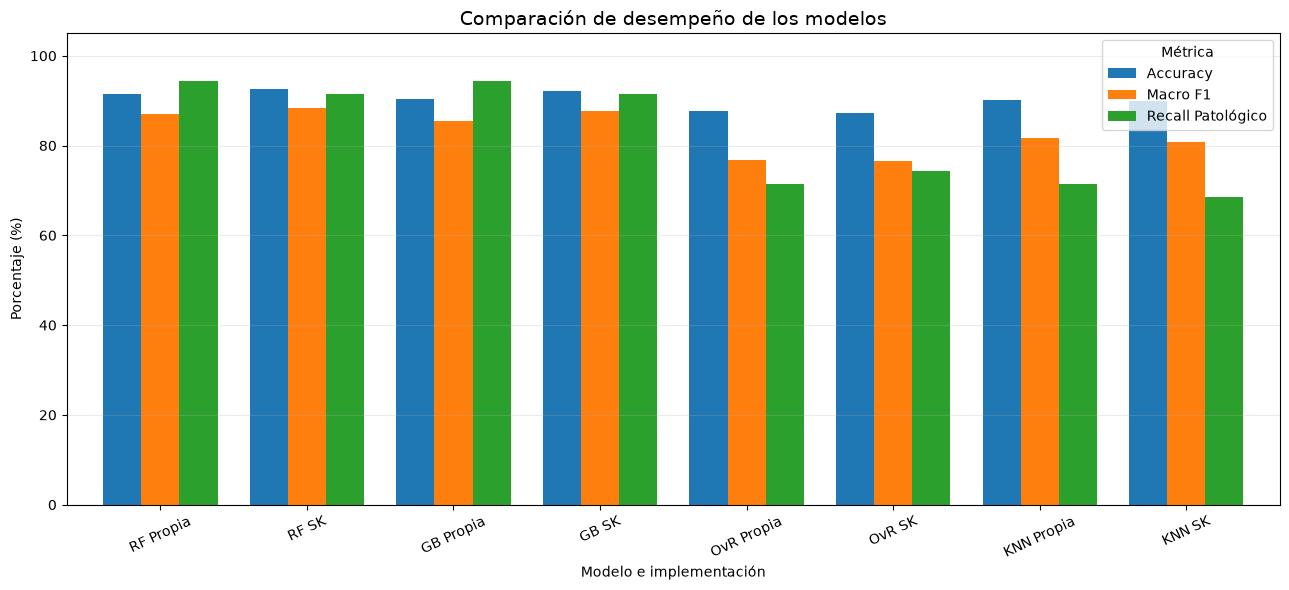

In [3]:
etiquetas = [
    "RF Propia", "RF SK", "GB Propia", "GB SK",
    "OvR Propia", "OvR SK", "KNN Propia", "KNN SK"
]
recall_patologico = [94.29, 91.43, 94.29, 91.43, 71.43, 74.29, 71.43, 68.57]

metricas_grafica = pd.DataFrame({
    "Accuracy": resultados["Accuracy (%)"].to_numpy(),
    "Macro F1": resultados["Macro F1 (%)"].to_numpy(),
    "Recall Patológico": recall_patologico
}, index=etiquetas)

ax = metricas_grafica.plot(kind="bar", figsize=(13, 6), width=0.78)
ax.set_title("Comparación de desempeño de los modelos", fontsize=14)
ax.set_ylabel("Porcentaje (%)")
ax.set_xlabel("Modelo e implementación")
ax.set_ylim(0, 105)
ax.grid(axis="y", alpha=0.25)
ax.tick_params(axis="x", rotation=25)
ax.legend(title="Métrica")
plt.tight_layout()
plt.show()


## 3. Desempeño por categoría

Las métricas globales no muestran por sí solas cómo se comporta cada modelo frente a las tres categorías. Por ello, se comparan los valores de Recall, que permiten identificar qué proporción de los registros reales de cada categoría fue clasificada correctamente.

También se incluyen la Precisión y el F1-Score de la clase Patológica para distinguir entre la cantidad de casos identificados y la confiabilidad de las predicciones asignadas a esa categoría.

In [4]:
metricas_clase = pd.DataFrame([
    ["Random Forest", "Propia", 93.35, 79.66, 94.29, 89.19, 91.67],
    ["Random Forest", "Scikit-learn", 96.37, 72.88, 91.43, 96.97, 94.12],
    ["Gradient Boosting", "Propia", 90.94, 84.75, 94.29, 82.50, 88.00],
    ["Gradient Boosting", "Scikit-learn", 94.56, 79.66, 91.43, 88.89, 90.14],
    ["Regresión Logística OvR", "Propia", 95.77, 52.54, 71.43, 89.29, 79.37],
    ["Regresión Logística OvR", "Scikit-learn", 94.86, 52.54, 74.29, 86.67, 80.00],
    ["KNN", "Propia", 97.28, 61.02, 71.43, 100.00, 83.33],
    ["KNN", "Scikit-learn", 97.28, 61.02, 68.57, 100.00, 81.36],
], columns=[
    "Modelo", "Implementación", "Recall Normal (%)", "Recall Sospechoso (%)",
    "Recall Patológico (%)", "Precisión Patológico (%)", "F1 Patológico (%)"
])

display(metricas_clase.style.format({col: "{:.2f}%" for col in metricas_clase.columns[2:]}))


,Modelo,Implementación,Recall Normal (%),Recall Sospechoso (%),Recall Patológico (%),Precisión Patológico (%),F1 Patológico (%)
0,Random Forest,Propia,93.35%,79.66%,94.29%,89.19%,91.67%
1,Random Forest,Scikit-learn,96.37%,72.88%,91.43%,96.97%,94.12%
2,Gradient Boosting,Propia,90.94%,84.75%,94.29%,82.50%,88.00%
3,Gradient Boosting,Scikit-learn,94.56%,79.66%,91.43%,88.89%,90.14%
4,Regresión Logística OvR,Propia,95.77%,52.54%,71.43%,89.29%,79.37%
5,Regresión Logística OvR,Scikit-learn,94.86%,52.54%,74.29%,86.67%,80.00%
6,KNN,Propia,97.28%,61.02%,71.43%,100.00%,83.33%
7,KNN,Scikit-learn,97.28%,61.02%,68.57%,100.00%,81.36%


### 3.1 Comparación del Recall por categoría

El siguiente gráfico permite observar las diferencias de sensibilidad entre los modelos.

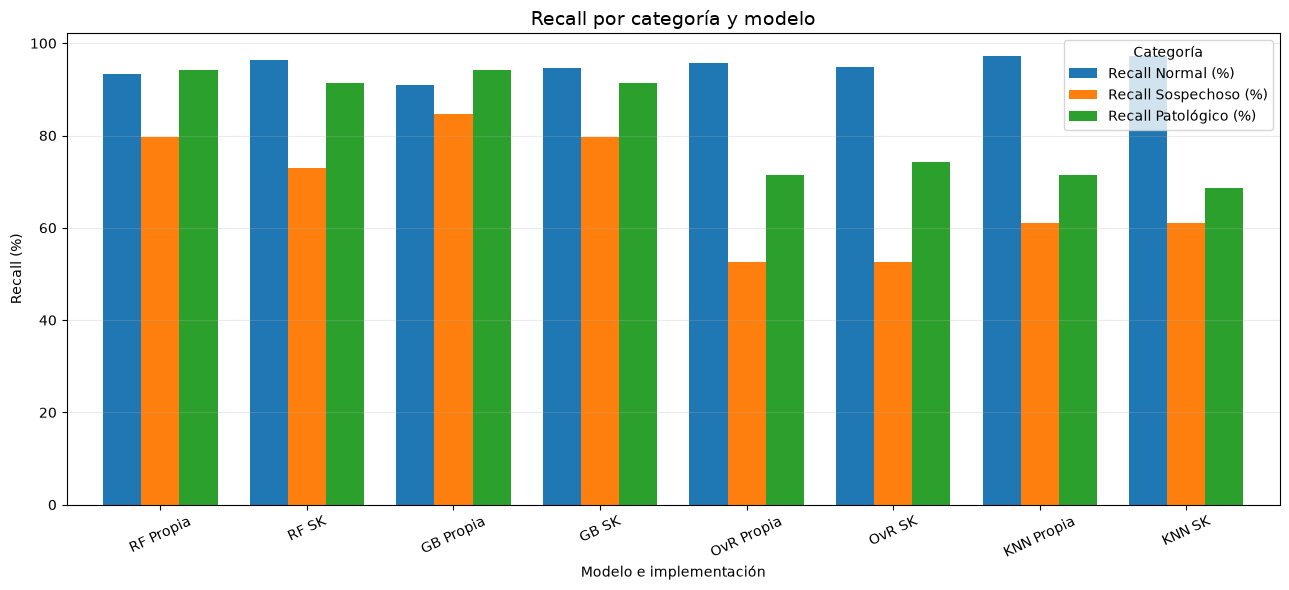

In [5]:
recall_por_clase = metricas_clase.set_index(
    ["Modelo", "Implementación"]
)[["Recall Normal (%)", "Recall Sospechoso (%)", "Recall Patológico (%)"]]

recall_por_clase.index = etiquetas
ax = recall_por_clase.plot(kind="bar", figsize=(13, 6), width=0.78)
ax.set_title("Recall por categoría y modelo", fontsize=14)
ax.set_ylabel("Recall (%)")
ax.set_xlabel("Modelo e implementación")
ax.grid(axis="y", alpha=0.25)
ax.tick_params(axis="x", rotation=25)
ax.legend(title="Categoría")
plt.tight_layout()
plt.show()


### 3.2 Interpretación del desempeño por categoría

- **Normal:** los ocho modelos muestran un Recall elevado. KNN y Regresión Logística OvR propia destacan en esta categoría, aunque ese resultado no implica que sean los mejores en las demás.

- **Sospechoso:** Gradient Boosting propio obtiene el mayor Recall (**84.75%**). Sin embargo, su Precisión en esta categoría es menor, por lo que identifica más registros sospechosos a costa de producir más falsas asignaciones a esa clase.

- **Patológico:** Random Forest propio y Gradient Boosting propio alcanzan el mayor Recall (**94.29%**), identificando correctamente 33 de los 35 registros Patológicos del conjunto de prueba. Random Forest propio obtiene una Precisión Patológica de **89.19%** y un F1-Score de **91.67%**.


**Diferencias en el comportamiento de los algoritmos:**

Los resultados muestran que los modelos de ensamble basados en árboles obtuvieron un desempeño general superior al de KNN y Regresión Logística OvR. Una posible explicación es su capacidad para representar relaciones no lineales e interacciones entre las características, sin depender de una frontera de decisión estrictamente lineal.

Asimismo, las estrategias de balanceo implementadas en nuestros modelos de Random Forest y Gradient Boosting pueden haber contribuido a mejorar el reconocimiento de las categorías minoritarias. En contraste, KNN y nuestra Regresión Logística OvR fueron entrenados utilizando la distribución original de las clases.

Es importante considerar que estas diferencias no pueden atribuirse exclusivamente al balanceo o a la arquitectura de los algoritmos, ya que existen otros factores como los hiperparámetros y los procedimientos de optimización que también influyen en los resultados.

## 4. Eficiencia computacional

Además del desempeño predictivo, se comparan los tiempos registrados durante el entrenamiento y la predicción en los notebooks individuales. Estos valores permiten describir el costo computacional observado para cada implementación.

> Los tiempos corresponden a mediciones de ejecuciones individuales y dependen del entorno, la carga del equipo y las condiciones de ejecución. Deben interpretarse como referencias de esta corrida, no como un benchmark controlado ni como una medición definitiva de complejidad algorítmica.

In [6]:
tiempos = pd.DataFrame([
    ["Random Forest", "Propia", 40.4624, 0.1557],
    ["Random Forest", "Scikit-learn", 0.4331, 0.0372],
    ["Gradient Boosting", "Propia", 58.7866, 0.1679],
    ["Gradient Boosting", "Scikit-learn", 1.7168, 0.0027],
    ["Regresión Logística OvR", "Propia", 0.6830, 0.0007],
    ["Regresión Logística OvR", "Scikit-learn", 0.0659, 0.0010],
    ["KNN", "Propia", 0.0006, 6.8244],
    ["KNN", "Scikit-learn", 0.0017, 2.1614],
], columns=["Modelo", "Implementación", "Entrenamiento (s)", "Predicción (s)"])

display(tiempos.style.format({
    "Entrenamiento (s)": "{:.4f}",
    "Predicción (s)": "{:.4f}"
}))


,Modelo,Implementación,Entrenamiento (s),Predicción (s)
0,Random Forest,Propia,40.4624,0.1557
1,Random Forest,Scikit-learn,0.4331,0.0372
2,Gradient Boosting,Propia,58.7866,0.1679
3,Gradient Boosting,Scikit-learn,1.7168,0.0027
4,Regresión Logística OvR,Propia,0.6830,0.0007
5,Regresión Logística OvR,Scikit-learn,0.0659,0.0010
6,KNN,Propia,0.0006,6.8244
7,KNN,Scikit-learn,0.0017,2.1614


### 4.1 Comparación de tiempos

Se presentan por separado los tiempos de entrenamiento y de predicción. 

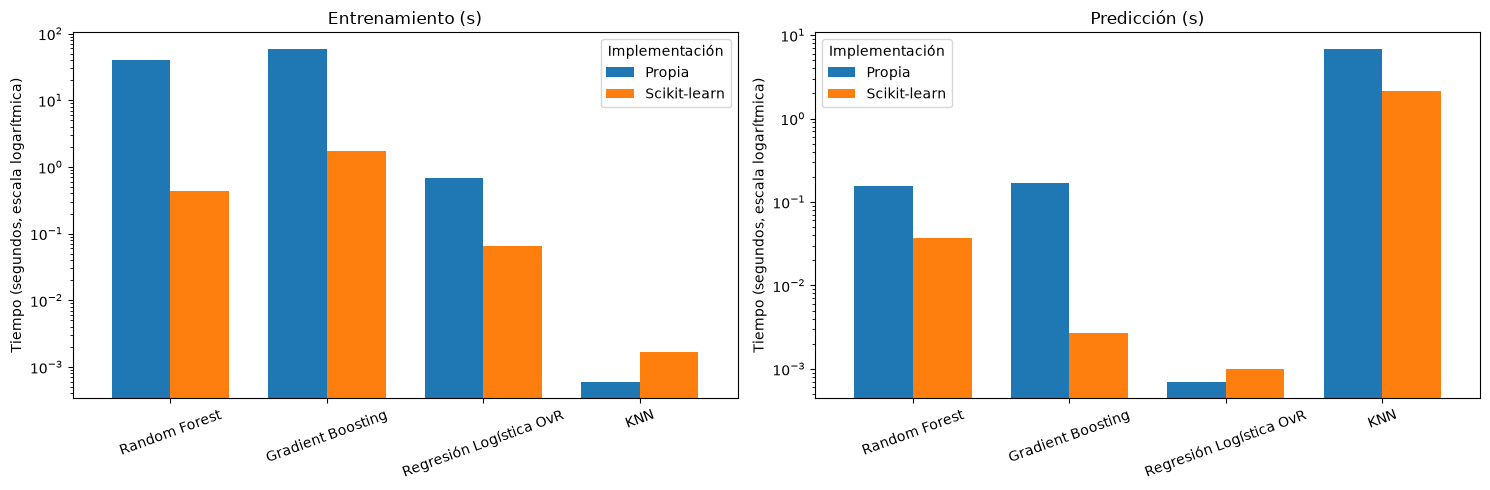

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

orden = [
    "Random Forest",
    "Gradient Boosting",
    "Regresión Logística OvR",
    "KNN"
]

for ax, col in zip(
    axes,
    ["Entrenamiento (s)", "Predicción (s)"]
):
    datos = tiempos.pivot(
        index="Modelo",
        columns="Implementación",
        values=col
    ).reindex(orden)

    datos[["Propia", "Scikit-learn"]].plot(
        kind="bar",
        ax=ax,
        width=0.75,
        logy=True
    )

    ax.set_title(col)
    ax.set_ylabel("Tiempo (segundos, escala logarítmica)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
    ax.legend(title="Implementación")

plt.tight_layout()
plt.show()





### 4.2 Interpretación de la eficiencia

- **Random Forest y Gradient Boosting:** las implementaciones de scikit-learn registran tiempos menores tanto en entrenamiento como en predicción. Las implementaciones propias requieren más tiempo, especialmente durante el entrenamiento.

- **Regresión Logística OvR:** ambas versiones presentan tiempos reducidos de predicción. scikit-learn registra un entrenamiento más rápido en esta ejecución.

- **KNN:** su entrenamiento es prácticamente inmediato porque almacena los registros. La mayor parte del costo aparece durante la búsqueda de vecinos en la predicción. En esta medición, la implementación propia tarda más que scikit-learn debido a la comparación de distancias euclidiana no optimizada que se uso.

Estas observaciones describen el comportamiento temporal medido en esta ejecución. El análisis de complejidad asintótica y el escalamiento con el tamaño del conjunto de datos se desarrollan por separado en el notebook de complejidad temporal.

## 5. Comparación global y selección de modelos

La selección depende de la prioridad establecida para el problema. 

Para valorar el desempeño general se consideran principalmente el Macro F1-Score, la Accuracy y el Macro AUC. 

Para revisar la detección de la categoría Patológica se consideran el Recall, la Precisión y el F1-Score de esa clase.

### Hallazgos principales

1. **Mejor desempeño general:** Random Forest de scikit-learn obtiene la mayor Accuracy (**92.71%**), el mayor Macro F1-Score (**88.36%**) y el mayor Macro AUC (**0.9792**) de las ocho configuraciones evaluadas.

2. **Mayor Recall Patológico:** Random Forest propio y Gradient Boosting propio empatan con **94.29%**, equivalente a 33 de 35 registros Patológicos identificados correctamente. Entre ambos, Random Forest propio presenta mayor Precisión Patológica (**89.19% frente a 82.50%**) y mayor F1 Patológico (**91.67% frente a 88.00%**).

3. **Mayor Recall Sospechoso:** Gradient Boosting propio obtiene **84.75%**, aunque con una Precisión de **65.79%** en esa categoría. Esta diferencia muestra el intercambio entre identificar más registros de esa clase y evitar falsas asignaciones.

4. **Eficiencia:** las implementaciones de scikit-learn suelen registrar menores tiempos de ejecución en los modelos. KNN presenta un comportamiento distinto: entrenamiento muy rápido y predicción más costosa.

### Selección de Modelo

Con los criterios globales, **Random Forest de scikit-learn es la configuración con mejor equilibrio general** en esta evaluación. Si se prioriza específicamente el Recall Patológico entre las implementaciones propias, Random Forest propio ofrece el mejor equilibrio de las dos versiones que alcanzan el 94.29% de Recall Patológico.

Por lo tanto, conviene presentar a Random Forest como la familia de modelos más competitiva en este experimento, distinguiendo entre su versión de scikit-learn (mejor desempeño global) y la implementación propia (mayor Recall Patológico observado). 

## 6. Limitaciones de la comparación

- **Tamaño de la categoría Patológica:** el conjunto de prueba contiene 35 registros Patológicos. Cada registro representa aproximadamente 2.86 puntos porcentuales de Recall, por lo que el resultado puede variar notablemente con pocos casos.

- **Diferencias de implementación:** las versiones propias y las de scikit-learn no son idénticas en regularización, balanceo, optimización y cálculo de puntuaciones. Las diferencias observadas deben interpretarse considerando esas configuraciones.

- **Tiempos de ejecución:** las mediciones provienen de ejecuciones individuales y pueden variar según el hardware y el entorno en el que sean ejecutadas.

- **Alcance de las predicciones:** los modelos clasifican la etiqueta NSP del conjunto de datos. Los resultados usados por nuestros modelos NO son un diagnóstico de grado clínico.

## 7. Conclusiones finales

La comparación nos permitió observar que los modelos obtuvieron en general, los resultados más competitivos en la clasificación de las tres categorías del estado fetal. 

En particular, Random Forest de scikit-learn alcanzó la mayor Accuracy (**92.71%**), el mayor Macro F1-Score (**88.36%**) y el mayor Macro AUC (**0.9792**), por lo que presentó el mejor equilibrio global dentro de las configuraciones evaluadas.

Por otra parte, las implementaciones propias de Random Forest y Gradient Boosting consiguieron el mayor Recall en la categoría Patológica (**94.29%**), identificando correctamente 33 de los 35 registros de esa clase en el conjunto de prueba. Entre ellas, Random Forest propio obtuvo una mayor Precisión y un mayor F1-Score Patológico. Gradient Boosting propio destacó en el Recall de la categoría Sospechosa (**84.75%**), aunque presentó una menor Precisión en esa misma categoría.

La Regresión Logística OvR obtuvo resultados competitivos como modelo lineal de referencia, pero presentó mayores dificultades para clasificar la categoría Sospechosa y un Recall Patológico inferior al de los modelos de ensamble. KNN mostró buenos resultados en la categoría Normal, pero su capacidad para identificar registros Patológicos fue menor y su tiempo de predicción fue considerablemente más alto en la implementación propia.

En conclusión, **Random Forest fue la familia de modelos más equilibrada en esta evaluación**, mientras que las diferencias por categoría muestran que la selección también depende de la métrica prioritaria. 

Finalmente, al tratarse de una evaluación basada en una única partición y en un conjunto de prueba con pocos registros Patológicos, los resultados deben considerarse  **experimentales**  . Sería necesario validar los modelos con otras particiones y datos independientes antes de plantear una aplicación fuera de un contexto meramente academico.

---

### Nota de mantenimiento

Cuando se actualicen las métricas de un notebook individual, también deben actualizarse las tablas de este cuaderno y volver a ejecutar sus gráficas. Los valores de esta versión corresponden a los resultados guardados en los notebooks revisados durante la elaboración de esta comparación.